# 01 · Video → per-frame facial signals  *(owner: Geethika)*

Runs `extract_features.py` (must be in the **same folder** as this notebook) on the UTA-RLDD videos and checks the output.

**Why a script instead of code in the notebook?** MediaPipe runs in several worker processes, and on Windows those cannot be started from functions defined inside a notebook.

**What it produces:** one small `features/<subject>_<label>.npz` per video, with timestamps and per-frame EAR (left/right), MAR, head pitch/yaw/roll, eyebrow distances and a face-found flag. Everything later runs on these files, so this step is done **once**.

**Before you start**
- `pip install mediapipe==0.10.14 opencv-python numpy pandas matplotlib` (Python 3.10–3.12). Newer MediaPipe releases removed the API the script uses.
- Close Chrome and other heavy apps. With ~8 GB RAM, use at most 3 workers.
- Expected layout: `<VIDEO_DIR>/**/<subject_id>/{0,5,10}.mov` (a video split into parts, e.g. `10_1.mp4` and `10_2.mp4`, is also handled) where 0 = alert, 5 = low vigilant, 10 = drowsy. Check this against your download in cell 2.

In [1]:
import sys, os, glob, time, subprocess
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

# ---------------- configuration ----------------
VIDEO_DIR = r"D:/RLDD"      # folder that contains the downloaded dataset
OUT_DIR   = "features"
STRIDE    = 2               # keep every 2nd frame (~15 fps for 30 fps video). Don't go above 2.
WORKERS   = 3               # parallel processes; raise only if RAM allows
MAX_WIDTH = 640             # frames wider than this are resized before landmark detection
LIMIT     = 0              # 2 = benchmark on 2 videos first.  Set to 0 for the full dataset.

In [2]:
# Check the dataset layout is what the script expects
LABELS = {"0": "alert", "5": "low", "10": "drowsy"}
def code(v): return os.path.splitext(os.path.basename(v))[0].split("_")[0]      # "10_1" -> "10"
vids = sorted(p for ext in ("mov", "mp4", "m4v", "avi", "mkv") for p in glob.glob(os.path.join(VIDEO_DIR, "**", f"*.{ext}"), recursive=True))
found = [(os.path.basename(os.path.dirname(v)), LABELS[code(v)], os.path.splitext(os.path.basename(v))[0], v)
         for v in vids if code(v) in LABELS]
chk = pd.DataFrame(found, columns=["subject", "label", "file", "path"])
print(f"{len(chk)} usable video files | {chk.subject.nunique()} subjects")
print(chk.label.value_counts().to_string())
odd = chk.groupby("subject").filter(lambda g: not (len(g) == 3 and g.label.nunique() == 3))
print(f"\nSubjects whose files are NOT exactly one alert + one low + one drowsy: {odd.subject.nunique()}")
display(odd.groupby("subject").file.apply(list).to_frame("files"))   # e.g. split drowsy videos (10_1, 10_2) or missing videos

0 usable video files | 0 subjects
Series([], )

Subjects whose files are NOT exactly one alert + one low + one drowsy: 0


,files
subject,


In [3]:
# Optional: how much RAM is free? (pip install psutil)
try:
    import psutil
    free = psutil.virtual_memory().available / 1e9
    print(f"Available RAM: {free:.1f} GB")
    if free < 1.0 * WORKERS + 1:
        print("WARNING: low RAM. Close other programs or reduce WORKERS.")
except ImportError:
    print("psutil not installed - skipping RAM check")

Available RAM: 0.8 GB


In [4]:
# Run the extraction (streams progress; mediapipe's noisy log lines are hidden)
cmd = [sys.executable, "extract_features.py", "--videos", VIDEO_DIR, "--out", OUT_DIR,
       "--stride", str(STRIDE), "--workers", str(WORKERS), "--max_width", str(MAX_WIDTH)]
if LIMIT:
    cmd += ["--limit", str(LIMIT)]

SKIP = ("W0000", "I0000", "INFO:", "WARNING:")
t0 = time.time()
with subprocess.Popen(cmd, stdout=subprocess.PIPE, stderr=subprocess.STDOUT, text=True) as p:
    for line in p.stdout:
        if not line.startswith(SKIP) and "TensorFlow Lite" not in line:
            print(line, end="")
elapsed = time.time() - t0
print(f"\nElapsed: {elapsed/60:.1f} min")
if LIMIT:
    parallel = min(LIMIT, WORKERS)                 # videos that ran at the same time
    print(f"Rough projection for all 180 videos: ~{elapsed * 180 / parallel / 3600:.1f} h "
          f"(assumes {parallel} videos ran in parallel and the benchmark videos are typical; very rough)")

0 videos found

Elapsed: 0.0 min


## Quality check

Look for: face found in most frames, a sensible frame rate, and an EAR trace where **blinks appear as clear dips**. If the face-found fraction is low for a video, that video's features will be unreliable.

In [5]:
rows = []
for f in sorted(glob.glob(os.path.join(OUT_DIR, "*.npz"))):
    d = np.load(f)
    X, t = d["X"], d["t"]
    cols = list(d["cols"])
    ear = np.nanmean(X[:, [cols.index("ear_l"), cols.index("ear_r")]], axis=1) if np.isfinite(X[:, 0]).any() else np.array([np.nan])
    subj, lab = os.path.basename(f)[:-4].split("_", 1)
    rows.append(dict(subject=subj, label=lab, frames=len(t), minutes=t[-1] / 60 if len(t) else 0,
                     eff_fps=1 / np.median(np.diff(t)) if len(t) > 1 else np.nan,
                     face_found=X[:, cols.index("face_found")].mean(),
                     ear_median=np.nanmedian(ear) if np.isfinite(ear).any() else np.nan))
qc = pd.DataFrame(rows)
display(qc.round(3))
bad = qc[qc.face_found < 0.8]
print(f"\nVideos with face found in <80% of frames: {len(bad)}")
if len(bad):
    display(bad.round(3))

C:\Users\HP\AppData\Local\Temp\ipykernel_23264\234817233.py:6: RuntimeWarning: Mean of empty slice
  ear = np.nanmean(X[:, [cols.index("ear_l"), cols.index("ear_r")]], axis=1) if np.isfinite(X[:, 0]).any() else np.array([np.nan])


,subject,label,frames,minutes,eff_fps,face_found,ear_median
0,01,alert,9027,10.039,14.983,1.000,0.289
1,01,drowsy,9006,10.016,14.983,0.999,0.273
2,01,low,8985,9.993,14.983,1.000,0.285
3,02,alert,9132,10.156,14.983,1.000,0.260
4,02,drowsy,9062,10.078,14.983,1.000,0.255
...,...,...,...,...,...,...,...
177,59,drowsy,9048,10.044,15.012,1.000,0.310
178,59,low,9085,10.085,15.012,1.000,0.305
179,60,alert,9027,10.074,14.934,1.000,0.267
180,60,drowsy,9291,10.459,14.803,1.000,0.276



Videos with face found in <80% of frames: 3


,subject,label,frames,minutes,eff_fps,face_found,ear_median
77,26,low,13223,14.688,15.004,0.379,0.248
133,45,alert,3859,10.288,6.250,0.368,0.229
147,49,drowsy_p2,17377,19.524,14.834,0.693,0.234


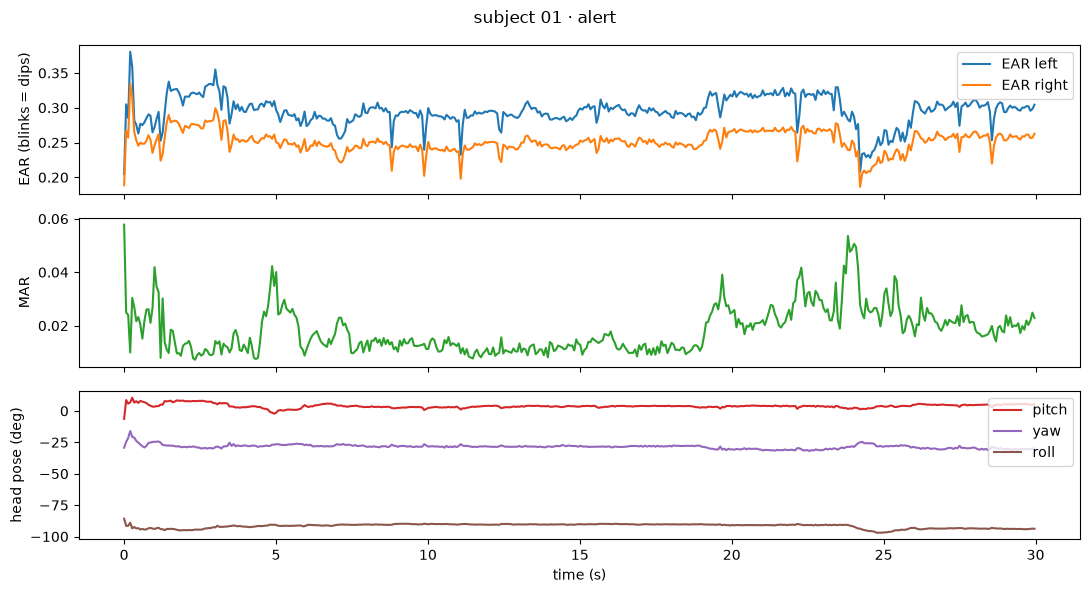

In [6]:
# Plot 30 s of EAR for the first video that has faces
good = qc[qc.face_found > 0.5]
if len(good) == 0:
    print("No video with detected faces yet - nothing to plot.")
else:
    r = good.iloc[0]
    d = np.load(os.path.join(OUT_DIR, f"{r.subject}_{r.label}.npz"))
    cols = list(d["cols"]); X, t = d["X"], d["t"]
    m = t < 30
    fig, ax = plt.subplots(3, 1, figsize=(11, 6), sharex=True)
    ax[0].plot(t[m], X[m, cols.index("ear_l")], label="EAR left"); ax[0].plot(t[m], X[m, cols.index("ear_r")], label="EAR right")
    ax[0].set_ylabel("EAR (blinks = dips)"); ax[0].legend(loc="upper right")
    ax[1].plot(t[m], X[m, cols.index("mar")], color="C2"); ax[1].set_ylabel("MAR")
    for k, c in zip(("pitch", "yaw", "roll"), ("C3", "C4", "C5")):
        ax[2].plot(t[m], X[m, cols.index(k)], color=c, label=k)
    ax[2].set_ylabel("head pose (deg)"); ax[2].set_xlabel("time (s)"); ax[2].legend(loc="upper right")
    fig.suptitle(f"subject {r.subject} · {r.label}"); plt.tight_layout(); plt.show()

## Next
1. If the quick benchmark looks right, set `LIMIT = 0` and re-run the extraction cell (finished videos are skipped, so it can be restarted).
2. To split the work across teammates, give each person a different part of the dataset folders. Share the resulting `.npz` files (only tens of MB in total) by merging them into one `features/` folder.
3. Hand the `features/` folder to Rithwika for notebook **02**.